In [14]:
# %%
# ============================================================
# 0. Imports e Configuração Global
# ============================================================

import os
import warnings
import time
from dataclasses import dataclass
from glob import glob

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.fft as fft

from scipy.io import loadmat
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

try:
    from tqdm.auto import tqdm
except ImportError:
    from tqdm import tqdm

try:
    import pywt
except ImportError:
    !pip install PyWavelets -q
    import pywt

# Reprodutibilidade
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [15]:
# %%
# ============================================================
# 1. Dataset MRI (BIRN)
# ============================================================

class MRIDataset(torch.utils.data.Dataset):
    """Carrega volumes .mat e extrai fatias 2D normalizadas para [0,1]."""
    def __init__(self, root):
        self.files = sorted(glob(os.path.join(root, "**", "*.mat"), recursive=True))
        if not self.files:
            raise RuntimeError(f"Nenhum arquivo .mat encontrado em {root}")

        self.images = []
        print("Lendo arquivos...")
        for file in tqdm(self.files):
            mat = loadmat(file)
            volume = None
            for key, value in mat.items():
                if key.startswith("__"):
                    continue
                if isinstance(value, np.ndarray) and value.ndim == 3:
                    volume = value.astype(np.float32)
                    break
            if volume is None:
                continue

            # Detecta orientação: (H,W,N) ou (N,H,W)
            if volume.shape[0] == volume.shape[1]:      # (H,W,N)
                for i in range(volume.shape[2]):
                    self.images.append(volume[:, :, i])
            else:                                       # (N,H,W)
                for i in range(volume.shape[0]):
                    self.images.append(volume[i])

        # Normalização global para [0,1]
        for i in range(len(self.images)):
            img = self.images[i]
            img = img - img.min()
            img = img / (img.max() + 1e-8)
            self.images[i] = img

        print(f"Total de slices carregadas: {len(self.images)}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return torch.from_numpy(self.images[idx]).float()

# Caminho do dataset: tenta os caminhos conhecidos e, se falhar, procura qualquer pasta com .mat
candidates = [
    "/kaggle/input/datasets/semnickcharlie/brain-dataset1",
    "/kaggle/input/datasets/semnickcharlie/brain-dataset",
    "/kaggle/input/brain-dataset1",
    "/kaggle/input/brain-dataset",
]
dataset_path = next((p for p in candidates if os.path.isdir(p)), None)
if dataset_path is None:
    for _root in ["/kaggle/input", "."]:
        for r, d, f in os.walk(_root):
            if any(fn.endswith(".mat") for fn in f):
                dataset_path = r
                break
        if dataset_path:
            break
print("dataset_path =", dataset_path)

try:
    dataset = MRIDataset(dataset_path)
except Exception as e:
    print(f"Erro ao carregar: {e}. Usando dataset sintético para demonstração.")
    class DummyDataset:
        def __init__(self, n=30):
            self.images = [np.random.rand(128, 128).astype(np.float32) for _ in range(n)]
            for i in range(n):
                self.images[i] = (self.images[i] - self.images[i].min()) / (self.images[i].max() + 1e-8)
        def __len__(self):
            return len(self.images)
        def __getitem__(self, idx):
            return torch.from_numpy(self.images[idx])
    dataset = DummyDataset(30)

dataset_path = /kaggle/input/datasets/semnickcharlie/brain-dataset1
Lendo arquivos...


  0%|          | 0/158 [00:00<?, ?it/s]

Total de slices carregadas: 4020


In [16]:
# %%
# ============================================================
# 2. Configuração do CS e Máscara ESPIRAL (variable-density)
# ============================================================
from functools import lru_cache

@dataclass
class CSConfig:
    # Wavelet
    wavelet: str = "db4"
    level: int = 3

    # Regularização (valores iniciais para continuação)
    lambda_wavelet_start: float = 0.008
    lambda_wavelet_end: float = 0.002
    lambda_tv_start: float = 0.003
    lambda_tv_end: float = 0.0005

    # Continuação
    use_continuation: bool = True
    schedule: str = "cosine"

    # Otimização
    max_iter: int = 150
    tolerance: float = 1e-6
    restart: bool = True

    # TV interna (5 iterações para acelerar)
    tv_inner_iter: int = 5
    verbose: bool = False

# ---------------- Parâmetros globais da amostragem espiral ----------------
ACCEL         = 4.0   # fator de aceleração (cobertura do k-space ≈ 1/ACCEL)
NUM_ARMS      = 4     # número de braços (interleaves) da espiral
DENSITY_POWER = 2.0   # 1.0 = densidade uniforme (ruim p/ CS); >1 = mais denso no centro
CENTER_RADIUS = 8     # disco central (baixas frequências) sempre amostrado


def _spiral_points(H, W, num_arms, turns, density_power, n_points):
    """Pontos (i, j) da espiral na convenção CENTRADA (DC em (H//2, W//2)),
    a mesma do MRIOperator: fftshift(fft2(x))."""
    cy, cx = H // 2, W // 2
    t = np.linspace(0.0, 1.0, n_points)
    r = t ** density_power                                   # raio normalizado [0, 1]
    ii, jj = [], []
    for a in np.linspace(0.0, 2 * np.pi, num_arms, endpoint=False):
        th = 2 * np.pi * turns * t + a
        ii.append(np.round(cy + r * np.sin(th) * (H / 2.0)).astype(int))
        jj.append(np.round(cx + r * np.cos(th) * (W / 2.0)).astype(int))
    ii, jj = np.concatenate(ii), np.concatenate(jj)
    ok = (ii >= 0) & (ii < H) & (jj >= 0) & (jj < W)
    return ii[ok], jj[ok]


def _build_spiral_mask(H, W, num_arms, turns, density_power, center_radius):
    n_points = int(max(H, W) * 400)                          # amostragem densa ao longo da curva
    m = np.zeros((H, W), dtype=np.float32)
    ii, jj = _spiral_points(H, W, num_arms, turns, density_power, n_points)
    m[ii, jj] = 1.0

    # Simetria de Hermite: se (k) é amostrado, (-k) também (imagem real => k-space Hermitiano)
    cy, cx = H // 2, W // 2
    I, J = np.indices((H, W))
    m = np.maximum(m, m[(2 * cy - I) % H, (2 * cx - J) % W])

    # Disco central totalmente amostrado
    if center_radius > 0:
        m[((I - cy) ** 2 + (J - cx) ** 2) <= center_radius ** 2] = 1.0
    return m


@lru_cache(maxsize=64)
def _spiral_mask_np(H, W, acceleration, num_arms, turns, density_power, center_radius):
    if turns is not None:
        return _build_spiral_mask(H, W, num_arms, turns, density_power, center_radius)

    # 'turns' automático: busca binária para a cobertura final ≈ 1/acceleration
    target = 1.0 / acceleration
    lo, hi = 0.25, float(max(H, W))
    for _ in range(25):
        mid = 0.5 * (lo + hi)
        cov = _build_spiral_mask(H, W, num_arms, mid, density_power, center_radius).mean()
        if cov < target:
            lo = mid
        else:
            hi = mid
    return _build_spiral_mask(H, W, num_arms, 0.5 * (lo + hi), density_power, center_radius)


def create_mask_spiral(shape, acceleration=ACCEL, num_arms=NUM_ARMS, turns=None,
                       density_power=DENSITY_POWER, center_radius=CENTER_RADIUS,
                       device="cpu"):
    """
    Máscara de amostragem espiral (variable-density) no k-space CENTRADO.

    - shape        : (H, W)
    - acceleration : fator de aceleração; a cobertura da máscara fica ≈ 1/acceleration
    - num_arms     : braços da espiral
    - turns        : voltas por braço. None => calculado automaticamente p/ atingir a aceleração
    - density_power: >1 concentra amostras nas baixas frequências (essencial para CS)
    - center_radius: raio do disco central sempre amostrado
    """
    H, W = int(shape[0]), int(shape[1])
    assert acceleration > 1.0, "acceleration deve ser > 1"
    m = _spiral_mask_np(H, W, float(acceleration), int(num_arms),
                        None if turns is None else float(turns),
                        float(density_power), int(center_radius))
    return torch.from_numpy(m.copy()).to(device)


# ---------------- Verificações rápidas (devem passar) ----------------
_m = create_mask_spiral((192, 192), ACCEL)
_c = 192 // 2
_idx = (2 * _c - np.arange(192)) % 192
_sym = bool((_m.numpy() == _m.numpy()[_idx][:, _idx]).all())
print(f"ACCEL={ACCEL} | cobertura = {_m.mean().item():.4f} (alvo {1/ACCEL:.4f}) | Hermitiana: {_sym}")
assert _sym, "A máscara precisa ser simétrica (k -> -k)"


ACCEL=4.0 | cobertura = 0.2499 (alvo 0.2500) | Hermitiana: True


In [17]:
# %%
# ============================================================
# 3. Operadores Lineares (Fourier, Wavelet, TV)
# ============================================================

class MRIOperator:
    """Operador A = M * F (com norm='ortho')."""
    def __init__(self, mask):
        self.mask = mask

    def forward(self, image):
        return fft.fftshift(fft.fft2(image, norm="ortho")) * self.mask

    def adjoint(self, kspace):
        # Multiplica pela máscara para segurança
        return torch.real(fft.ifft2(fft.ifftshift(kspace * self.mask), norm="ortho"))

    def zero_filled(self, measured):
        return self.adjoint(measured)

class WaveletOperator:
    """Operador wavelet com armazenamento das fatias para inversão rápida."""
    def __init__(self, wavelet="db4", level=3):
        self.wavelet = wavelet
        self.level = level
        self.coeff_slices = None
        self.coeff_shape = None

    def _initialize(self, shape):
        if self.coeff_shape == shape:
            return
        dummy = np.zeros(shape)
        coeffs = pywt.wavedec2(dummy, self.wavelet, level=self.level, mode="periodization")
        _, slices = pywt.coeffs_to_array(coeffs)
        self.coeff_slices = slices
        self.coeff_shape = shape

    def forward(self, img):
        if torch.is_tensor(img):
            img = img.detach().cpu().numpy()
        self._initialize(img.shape)
        coeffs = pywt.wavedec2(img, self.wavelet, level=self.level, mode="periodization")
        arr, _ = pywt.coeffs_to_array(coeffs)
        return arr

    def inverse(self, arr):
        coeffs = pywt.array_to_coeffs(arr, self.coeff_slices, output_format="wavedec2")
        img = pywt.waverec2(coeffs, self.wavelet, mode="periodization")
        H, W = self.coeff_shape
        return torch.tensor(img[:H, :W], dtype=torch.float32)

def soft_threshold(coeffs, lam):
    return np.sign(coeffs) * np.maximum(np.abs(coeffs) - lam, 0.0)

def tv_denoise_chambolle(image, weight=0.01, max_iter=5, eps=1e-4):
    """
    Projeção de Chambolle para TV denoising (acelerada com poucas iterações).
    """
    px = torch.zeros_like(image)
    py = torch.zeros_like(image)
    tau = 0.25
    u = image.clone()
    for _ in range(max_iter):
        u_old = u.clone()
        gradx = torch.zeros_like(u)
        grady = torch.zeros_like(u)
        gradx[:-1, :] = u[1:, :] - u[:-1, :]
        grady[:, :-1] = u[:, 1:] - u[:, :-1]

        px = px + tau * gradx
        py = py + tau * grady
        norm = torch.maximum(torch.ones_like(px), torch.sqrt(px**2 + py**2))
        px /= norm
        py /= norm

        div = torch.zeros_like(u)
        div[1:, :] += px[:-1, :]
        div[:-1, :] -= px[:-1, :]
        div[:, 1:] += py[:, :-1]
        div[:, :-1] -= py[:, :-1]

        u = image + weight * div
        if torch.norm(u - u_old) < eps:
            break
    return u

In [18]:
# %%
# ============================================================
# 4. FISTA com Wavelet L1 + TV
# ============================================================

class LambdaScheduler:
    """Decaimento dos parâmetros de regularização."""
    def __init__(self, lambda_start, lambda_end, max_iter, schedule="cosine"):
        self.lambda_start = lambda_start
        self.lambda_end = lambda_end
        self.max_iter = max_iter
        self.schedule = schedule

    def __call__(self, iteration):
        t = iteration / max(self.max_iter - 1, 1)
        if self.schedule == "linear":
            alpha = t
        elif self.schedule == "quadratic":
            alpha = t**2
        elif self.schedule == "cosine":
            alpha = 0.5 * (1 - np.cos(np.pi * t))
        else:
            alpha = t
        return self.lambda_start * (1 - alpha) + self.lambda_end * alpha

def fidelity_gradient(image, operator, measured):
    """Gradiente de ||A x - y||_2^2."""
    residual = operator.forward(image) - measured
    return operator.adjoint(residual)

def objective(image, operator, measured, wavelet, lambda_w, lambda_tv):
    """Função objetivo: 1/2||Ax-y||² + λ_w||Wx||₁ + λ_tv TV(x)."""
    residual = operator.forward(image) - measured
    fidelity = 0.5 * torch.sum(torch.abs(residual)**2).item()

    coeff = wavelet.forward(image)
    sparsity = lambda_w * np.sum(np.abs(coeff))

    # TV isotrópica com alinhamento correto
    gx = image[1:, :] - image[:-1, :]
    gy = image[:, 1:] - image[:, :-1]
    gx = gx[:, :-1]
    gy = gy[:-1, :]
    tv = lambda_tv * torch.sum(torch.sqrt(gx**2 + gy**2 + 1e-8)).item()

    return fidelity + sparsity + tv

class FISTA:
    def __init__(self, config):
        self.config = config
        self.wavelet = WaveletOperator(config.wavelet, config.level)

    def solve(self, measured, mask):
        operator = MRIOperator(mask)
        L = 1.0  # FFT ortonormal + máscara binária → Lipschitz = 1

        # Inicialização
        x = operator.zero_filled(measured)
        y = x.clone()
        t = 1.0

        history = []
        objectives = []

        # Schedulers
        if self.config.use_continuation:
            wv_sched = LambdaScheduler(
                self.config.lambda_wavelet_start,
                self.config.lambda_wavelet_end,
                self.config.max_iter,
                self.config.schedule
            )
            tv_sched = LambdaScheduler(
                self.config.lambda_tv_start,
                self.config.lambda_tv_end,
                self.config.max_iter,
                self.config.schedule
            )
        else:
            wv_sched = lambda it: self.config.lambda_wavelet_start
            tv_sched = lambda it: self.config.lambda_tv_start

        for it in range(self.config.max_iter):
            x_prev = x.clone()

            # 1. Gradiente da fidelidade
            grad = fidelity_gradient(y, operator, measured)

            # 2. Passo de descida (L=1)
            x = y - grad

            # 3. Proximal Wavelet L1
            lambda_w = wv_sched(it)
            coeff = self.wavelet.forward(x)
            coeff = soft_threshold(coeff, lambda_w / L)
            x = self.wavelet.inverse(coeff).to(measured.device)

            # 4. Proximal TV (Chambolle, com poucas iterações)
            lambda_tv = tv_sched(it)
            if lambda_tv > 0:
                x = tv_denoise_chambolle(x, weight=lambda_tv, max_iter=self.config.tv_inner_iter)

            # 5. Atualização de FISTA
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
            y = x + ((t - 1) / t_new) * (x - x_prev)

            # 6. Restart adaptativo (condição clássica de Beck-Teboulle)
            if self.config.restart:
                if torch.sum((x - y) * (x - x_prev)) > 0:
                    t = 1.0
                    y = x.clone()
                else:
                    t = t_new
            else:
                t = t_new

            # 7. Histórico
            if it % 10 == 0 or it == self.config.max_iter - 1:
                obj = objective(x, operator, measured, self.wavelet, lambda_w, lambda_tv)
                objectives.append(obj)
                history.append(x.detach().cpu())

            # Critério de parada
            change = torch.norm(x - x_prev) / (torch.norm(x_prev) + 1e-8)
            if change < self.config.tolerance:
                if self.config.verbose:
                    print(f"Convergência na iteração {it+1}")
                break

        return x, history, objectives

In [19]:
# %%
# ============================================================
# 5. Métricas e Avaliação em 30 imagens (máscara espiral)
# ============================================================

def nmse_np(gt, pred):
    return np.sum((gt - pred)**2) / (np.sum(gt**2) + 1e-12)

def compute_metrics(gt, pred):
    """Calcula PSNR, SSIM e NMSE entre imagens já normalizadas [0,1]."""
    gt = np.clip(gt, 0, 1)
    pred = np.clip(pred, 0, 1)
    psnr = peak_signal_noise_ratio(gt, pred, data_range=1.0)
    ssim = structural_similarity(gt, pred, data_range=1.0)
    nmse = nmse_np(gt, pred)
    return psnr, ssim, nmse

def evaluate_baseline(dataset, config, acceleration, n_images=30, device='cuda'):
    """Avalia o CS (Wavelet + TV) em n_images e retorna DataFrame."""
    results = []
    reconstructor = FISTA(config)

    for idx in tqdm(range(min(n_images, len(dataset))), desc="Reconstruindo"):
        gt = dataset[idx].to(device)
        mask = create_mask_spiral(gt.shape, acceleration, device=device)
        operator = MRIOperator(mask)
        kspace_us = operator.forward(gt)

        t0 = time.time()
        rec, _, _ = reconstructor.solve(kspace_us, mask)
        t_cs = time.time() - t0

        # Zero-filled (rápido)
        zf = operator.zero_filled(kspace_us)

        gt_np = gt.cpu().numpy()
        zf_np = zf.cpu().numpy()
        rec_np = rec.cpu().numpy()

        psnr_zf, ssim_zf, nmse_zf = compute_metrics(gt_np, zf_np)
        psnr_cs, ssim_cs, nmse_cs = compute_metrics(gt_np, rec_np)

        results.append([idx, psnr_zf, psnr_cs, ssim_zf, ssim_cs, nmse_zf, nmse_cs, t_cs])

    df = pd.DataFrame(results, columns=["idx", "psnr_zf", "psnr_cs", "ssim_zf", "ssim_cs",
                                        "nmse_zf", "nmse_cs", "time_cs"])
    return df

# Configuração ajustada (use os melhores parâmetros do grid search se já tiver)
config = CSConfig(
    lambda_wavelet_start=0.012,
    lambda_wavelet_end=0.003,
    lambda_tv_start=0.0002,
    lambda_tv_end=0.00005,
    max_iter=150,
    tv_inner_iter=5,
    use_continuation=True,
    restart=True,
    schedule="cosine",
    verbose=False
)

print("Configuração:")
print(config)
print(f"ACCEL = {ACCEL}x | braços = {NUM_ARMS} | density_power = {DENSITY_POWER}")

# Avalia em 30 imagens
df_results = evaluate_baseline(dataset, config, ACCEL, n_images=30, device=device)

# Salva resultados
df_results.to_csv("resultados_cs_spiral.csv", index=False)
print("\nResultados salvos em 'resultados_cs_spiral.csv'.")

Configuração:
CSConfig(wavelet='db4', level=3, lambda_wavelet_start=0.012, lambda_wavelet_end=0.003, lambda_tv_start=0.0002, lambda_tv_end=5e-05, use_continuation=True, schedule='cosine', max_iter=150, tolerance=1e-06, restart=True, tv_inner_iter=5, verbose=False)
ACCEL = 4.0x | braços = 4 | density_power = 2.0


Reconstruindo:   0%|          | 0/30 [00:00<?, ?it/s]


Resultados salvos em 'resultados_cs_spiral.csv'.



=== SUMÁRIO COMPARATIVO (Wavelet + TV, 30 imagens) ===

                                      PSNR (dB)             SSIM  \
Zero-filled                        28.54 ± 1.79  0.6439 ± 0.0460   
Compressed Sensing (Wavelet + TV)  31.14 ± 3.07  0.7704 ± 0.0692   

                                              NMSE   Tempo CS (s)  
Zero-filled                        0.0368 ± 0.0090  1.179 ± 0.027  
Compressed Sensing (Wavelet + TV)  0.0223 ± 0.0090  1.179 ± 0.027  


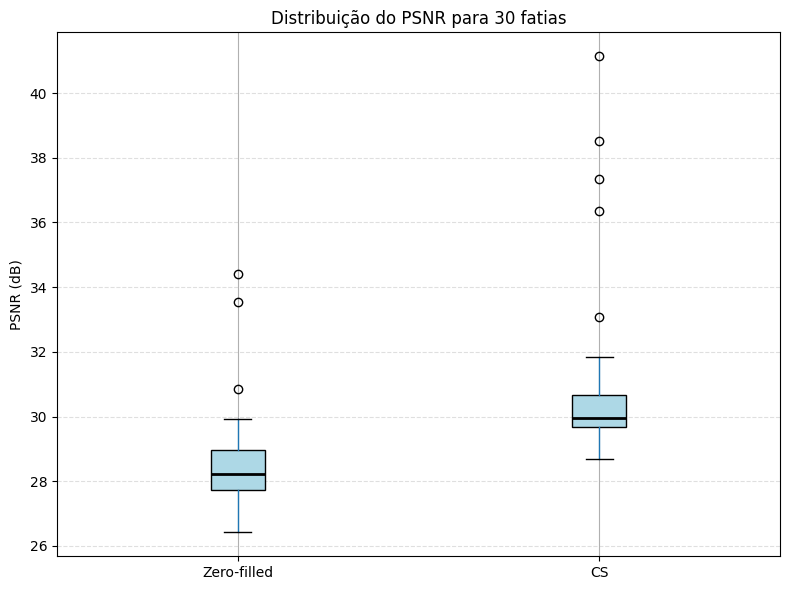


=== TESTE DE SIGNIFICÂNCIA ESTATÍSTICA (Wilcoxon) ===
Estatística W = 0.00
p-valor = 0.0000000009
✅ Diferença estatisticamente significativa (p < 0.05).


In [20]:
# %%
# ============================================================
# 6. Sumário Estatístico e Teste de Wilcoxon
# ============================================================

# Sumário
summary = pd.DataFrame({
    "PSNR (dB)": [
        f"{df_results.psnr_zf.mean():.2f} ± {df_results.psnr_zf.std():.2f}",
        f"{df_results.psnr_cs.mean():.2f} ± {df_results.psnr_cs.std():.2f}",
    ],
    "SSIM": [
        f"{df_results.ssim_zf.mean():.4f} ± {df_results.ssim_zf.std():.4f}",
        f"{df_results.ssim_cs.mean():.4f} ± {df_results.ssim_cs.std():.4f}",
    ],
    "NMSE": [
        f"{df_results.nmse_zf.mean():.4f} ± {df_results.nmse_zf.std():.4f}",
        f"{df_results.nmse_cs.mean():.4f} ± {df_results.nmse_cs.std():.4f}",
    ],
    "Tempo CS (s)": [
        f"{df_results.time_cs.mean():.3f} ± {df_results.time_cs.std():.3f}",
        f"{df_results.time_cs.mean():.3f} ± {df_results.time_cs.std():.3f}",
    ]
}, index=["Zero-filled", "Compressed Sensing (Wavelet + TV)"])

print("\n=== SUMÁRIO COMPARATIVO (Wavelet + TV, 30 imagens) ===\n")
print(summary)

# Boxplot
plt.figure(figsize=(8, 6))
df_box = pd.DataFrame({'Zero-filled': df_results['psnr_zf'], 'CS': df_results['psnr_cs']})
df_box.boxplot(patch_artist=True, 
               boxprops=dict(facecolor='lightblue'),
               medianprops=dict(color='black', linewidth=2))
plt.title('Distribuição do PSNR para 30 fatias')
plt.ylabel('PSNR (dB)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('boxplot_psnr_comparacao_spiral.png', dpi=150)
plt.show()

# Teste de Wilcoxon
from scipy.stats import wilcoxon
stat, p_val = wilcoxon(df_results['psnr_zf'], df_results['psnr_cs'], alternative='less')
print("\n=== TESTE DE SIGNIFICÂNCIA ESTATÍSTICA (Wilcoxon) ===")
print(f"Estatística W = {stat:.2f}")
print(f"p-valor = {p_val:.10f}")
if p_val < 0.05:
    print("✅ Diferença estatisticamente significativa (p < 0.05).")
else:
    print("⚠️  Diferença não significativa.")

In [21]:
# %%
# ============================================================
# 7. Grid Search Estendido (máscara espiral)
# ============================================================

def grid_search_parameters_extended(dataset, device, acceleration,
                                    wavelet_values=None,
                                    tv_values=None,
                                    n_images=10):
    """
    Grid search com faixa estendida para confirmar o ótimo.
    """
    if wavelet_values is None:
        wavelet_values = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]
    if tv_values is None:
        tv_values = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]

    results = []
    for lw in wavelet_values:
        for ltv in tv_values:
            print(f"\nλw={lw:.5f} | λtv={ltv:.5f}")
            cfg = CSConfig(
                lambda_wavelet_start=lw, lambda_wavelet_end=lw*0.25,
                lambda_tv_start=ltv, lambda_tv_end=ltv*0.25,
                max_iter=100,
                tv_inner_iter=5,
                use_continuation=True
            )
            rec = FISTA(cfg)
            psnrs = []
            for idx in range(min(n_images, len(dataset))):
                gt = dataset[idx].to(device)
                mask = create_mask_spiral(gt.shape, acceleration, device=device)
                kspace_us = MRIOperator(mask).forward(gt)
                x, _, _ = rec.solve(kspace_us, mask)
                p, _, _ = compute_metrics(gt.cpu().numpy(), x.cpu().numpy())
                psnrs.append(p)
            mean_psnr = np.mean(psnrs)
            results.append({"lw": lw, "ltv": ltv, "psnr": mean_psnr})
            print(f"  PSNR médio: {mean_psnr:.2f} dB")

    df_grid = pd.DataFrame(results)
    best = df_grid.loc[df_grid.psnr.idxmax()]
    print("\n=== MELHORES PARÂMETROS (GRID ESTENDIDO) ===")
    print(best)
    return df_grid

# Executa (pode levar alguns minutos)
print("Rodando grid search estendido com 10 imagens...")
print("Faixa: λw = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]")
print("       λtv = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]\n")

df_grid_ext = grid_search_parameters_extended(
    dataset, device, ACCEL,
    wavelet_values=[0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050],
    tv_values=[0.00005, 0.0001, 0.0002, 0.0005, 0.001],
    n_images=10
)

df_grid_ext.to_csv("grid_search_extended_spiral.csv", index=False)
print("\n=== TOP 10 RESULTADOS ===")
display(df_grid_ext.sort_values("psnr", ascending=False).head(10))

Rodando grid search estendido com 10 imagens...
Faixa: λw = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]
       λtv = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]


λw=0.00500 | λtv=0.00005
  PSNR médio: 30.27 dB

λw=0.00500 | λtv=0.00010
  PSNR médio: 30.27 dB

λw=0.00500 | λtv=0.00020
  PSNR médio: 30.26 dB

λw=0.00500 | λtv=0.00050
  PSNR médio: 30.23 dB

λw=0.00500 | λtv=0.00100
  PSNR médio: 30.19 dB

λw=0.01000 | λtv=0.00005
  PSNR médio: 30.30 dB

λw=0.01000 | λtv=0.00010
  PSNR médio: 30.30 dB

λw=0.01000 | λtv=0.00020
  PSNR médio: 30.29 dB

λw=0.01000 | λtv=0.00050
  PSNR médio: 30.28 dB

λw=0.01000 | λtv=0.00100
  PSNR médio: 30.26 dB

λw=0.01500 | λtv=0.00005
  PSNR médio: 30.32 dB

λw=0.01500 | λtv=0.00010
  PSNR médio: 30.32 dB

λw=0.01500 | λtv=0.00020
  PSNR médio: 30.32 dB

λw=0.01500 | λtv=0.00050
  PSNR médio: 30.31 dB

λw=0.01500 | λtv=0.00100
  PSNR médio: 30.30 dB

λw=0.02000 | λtv=0.00005
  PSNR médio: 30.33 dB

λw=0.02000 | λtv=0.00010
  PSNR médio: 30.33 dB

λ

,lw,ltv,psnr
15,0.020,0.00005,30.327945
16,0.020,0.00010,30.327482
17,0.020,0.00020,30.324980
10,0.015,0.00005,30.320635
18,0.020,0.00050,30.320188
11,0.015,0.00010,30.319618
20,0.030,0.00005,30.318809
21,0.030,0.00010,30.318753
22,0.030,0.00020,30.317245
12,0.015,0.00020,30.316453


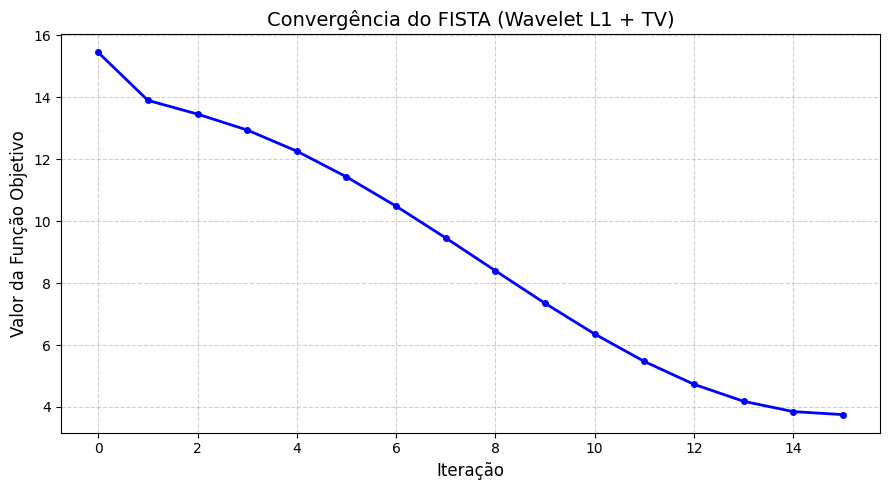

Objetivo final: 3.7540 | Iterações: 16


In [22]:
# %%
# ============================================================
# 8. Curva de Convergência do FISTA
# ============================================================

def plot_convergence(dataset, idx, config, acceleration, device):
    gt = dataset[idx].to(device)
    mask = create_mask_spiral(gt.shape, acceleration, device=device)
    operator = MRIOperator(mask)
    kspace_us = operator.forward(gt)

    rec = FISTA(config)
    _, _, obj_hist = rec.solve(kspace_us, mask)

    plt.figure(figsize=(9, 5))
    plt.plot(obj_hist, 'b-', linewidth=2, marker='o', markersize=4)
    plt.xlabel('Iteração', fontsize=12)
    plt.ylabel('Valor da Função Objetivo', fontsize=12)
    plt.title('Convergência do FISTA (Wavelet L1 + TV)', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig('convergencia_fista_spiral.png', dpi=150)
    plt.show()
    print(f"Objetivo final: {obj_hist[-1]:.4f} | Iterações: {len(obj_hist)}")

# Plota para a primeira fatia
plot_convergence(dataset, idx=0, config=config, acceleration=ACCEL, device=device)

=== AVALIANDO ACELERAÇÃO (ESPIRAL) ===
Acelerações: [2, 3, 4, 6, 8]



Acelerações:   0%|          | 0/5 [00:00<?, ?it/s]


=== QUALIDADE vs ACELERAÇÃO ===

 accel  cobertura   PSNR_zf  PSNR_mean  PSNR_std  SSIM_zf  SSIM_mean  SSIM_std
     2   0.500000 36.514880  40.454549  0.670191 0.874794   0.969928  0.002962
     3   0.333333 31.324485  33.715423  0.807079 0.734023   0.857939  0.013660
     4   0.250000 28.740927  30.306519  0.726444 0.656839   0.745396  0.021810
     6   0.166667 26.622042  26.250212  0.597680 0.593149   0.610740  0.021275
     8   0.125000 25.773620  23.861092  0.721185 0.570050   0.530696  0.029724


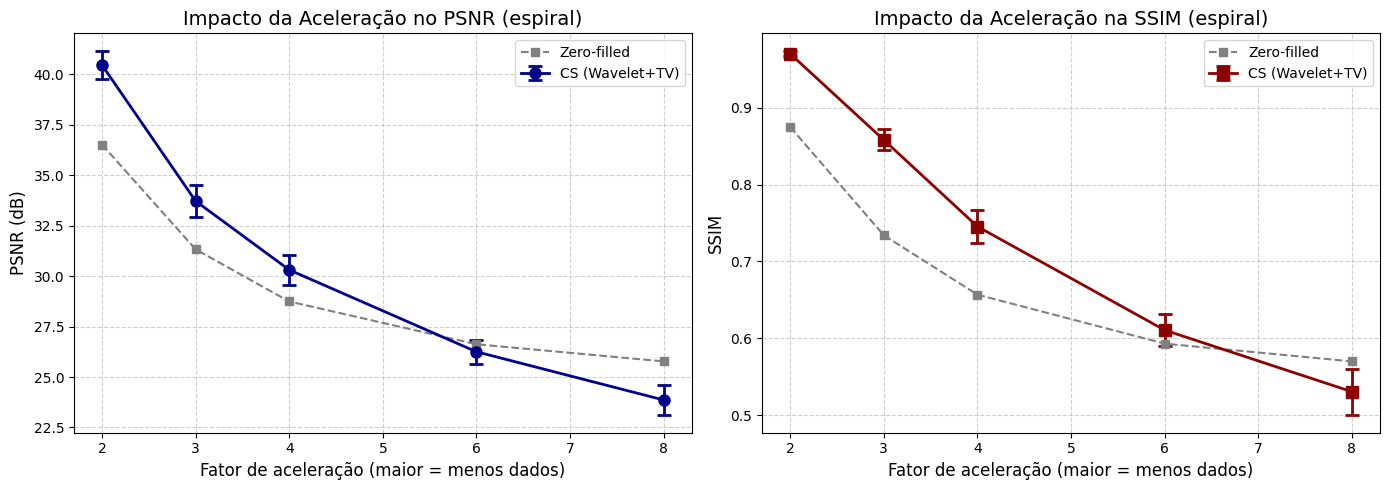

In [23]:
# %%
# ============================================================
# 9. Estudo da Aceleração (espiral)
# ============================================================

def evaluate_acceleration(dataset, accel_values, config, n_images=10, device='cuda'):
    results = []
    for acc in tqdm(accel_values, desc="Acelerações"):
        psnrs, ssims = [], []
        psnrs_zf, ssims_zf = [], []
        for idx in range(min(n_images, len(dataset))):
            gt = dataset[idx].to(device)
            mask = create_mask_spiral(gt.shape, acc, device=device)
            operator = MRIOperator(mask)
            kspace_us = operator.forward(gt)

            zf = operator.zero_filled(kspace_us)
            x, _, _ = FISTA(config).solve(kspace_us, mask)

            gt_np = gt.cpu().numpy()
            p0, s0, _ = compute_metrics(gt_np, zf.cpu().numpy())
            p, s, _ = compute_metrics(gt_np, x.cpu().numpy())
            psnrs_zf.append(p0); ssims_zf.append(s0)
            psnrs.append(p);     ssims.append(s)

        results.append({
            'accel': acc,
            'cobertura': 1.0 / acc,
            'PSNR_zf': np.mean(psnrs_zf),
            'PSNR_mean': np.mean(psnrs),
            'PSNR_std': np.std(psnrs),
            'SSIM_zf': np.mean(ssims_zf),
            'SSIM_mean': np.mean(ssims),
            'SSIM_std': np.std(ssims),
        })
    return pd.DataFrame(results)

accel_values = [2, 3, 4, 6, 8]   # quanto MAIOR, mais acelerado (menos dados)

print("=== AVALIANDO ACELERAÇÃO (ESPIRAL) ===")
print(f"Acelerações: {accel_values}\n")

df_accel = evaluate_acceleration(dataset, accel_values, config, n_images=10, device=device)

print("\n=== QUALIDADE vs ACELERAÇÃO ===\n")
print(df_accel.to_string(index=False))
df_accel.to_csv("aceleracao_spiral.csv", index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.errorbar(df_accel['accel'], df_accel['PSNR_mean'], yerr=df_accel['PSNR_std'],
             fmt='o-', capsize=5, capthick=2, linewidth=2, color='darkblue', markersize=8, label='CS (Wavelet+TV)')
ax1.plot(df_accel['accel'], df_accel['PSNR_zf'], 's--', color='gray', label='Zero-filled')
ax1.set_xlabel('Fator de aceleração (maior = menos dados)', fontsize=12)
ax1.set_ylabel('PSNR (dB)', fontsize=12)
ax1.set_title('Impacto da Aceleração no PSNR (espiral)', fontsize=14)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

ax2.errorbar(df_accel['accel'], df_accel['SSIM_mean'], yerr=df_accel['SSIM_std'],
             fmt='s-', capsize=5, capthick=2, linewidth=2, color='darkred', markersize=8, label='CS (Wavelet+TV)')
ax2.plot(df_accel['accel'], df_accel['SSIM_zf'], 's--', color='gray', label='Zero-filled')
ax2.set_xlabel('Fator de aceleração (maior = menos dados)', fontsize=12)
ax2.set_ylabel('SSIM', fontsize=12)
ax2.set_title('Impacto da Aceleração na SSIM (espiral)', fontsize=14)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('aceleracao_vs_qualidade_spiral.png', dpi=150)
plt.show()


Shape das imagens: (256, 256)

accel = 2x  →  amostrados =  32753 de 65536  (cobertura 0.500 | alvo 0.500)
accel = 3x  →  amostrados =  21833 de 65536  (cobertura 0.333 | alvo 0.333)
accel = 4x  →  amostrados =  16393 de 65536  (cobertura 0.250 | alvo 0.250)
accel = 6x  →  amostrados =  10921 de 65536  (cobertura 0.167 | alvo 0.167)
accel = 8x  →  amostrados =   8181 de 65536  (cobertura 0.125 | alvo 0.125)


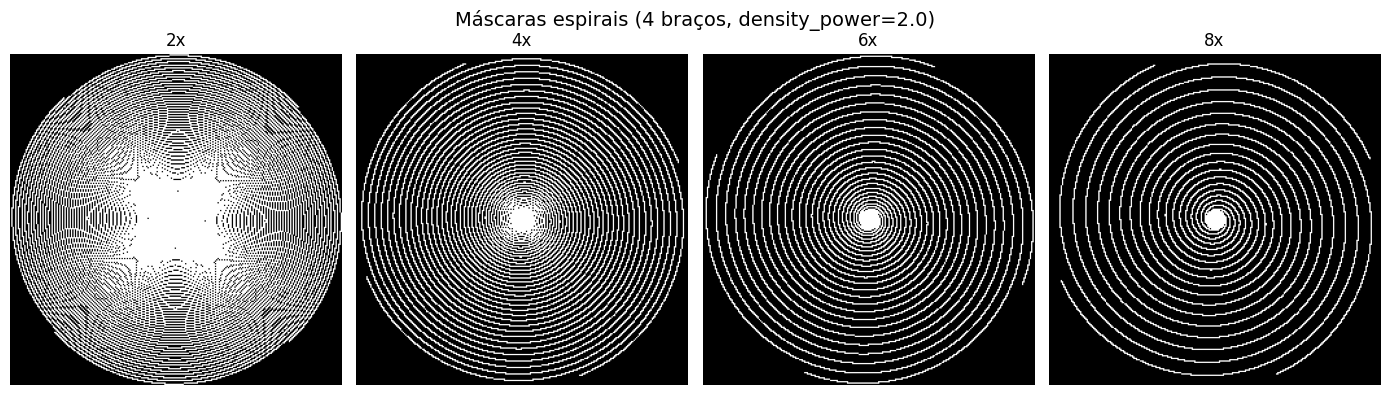

In [24]:
# %%
# ============================================================
# 10. Verificação: máscara espiral vs aceleração
# ============================================================

shape_chk = tuple(dataset[0].shape)
H, W = shape_chk
print(f"Shape das imagens: {shape_chk}\n")

for acc in [2, 3, 4, 6, 8]:
    mask = create_mask_spiral(shape_chk, acc, device='cpu')
    n = torch.sum(mask).item()
    print(f"accel = {acc}x  →  amostrados = {n:6.0f} de {H*W}  (cobertura {n/(H*W):.3f} | alvo {1/acc:.3f})")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, acc in zip(axes, [2, 4, 6, 8]):
    ax.imshow(create_mask_spiral(shape_chk, acc, device='cpu'), cmap='gray')
    ax.set_title(f'{acc}x')
    ax.axis('off')
plt.suptitle(f'Máscaras espirais ({NUM_ARMS} braços, density_power={DENSITY_POWER})', fontsize=14)
plt.tight_layout()
plt.show()


In [25]:
# %%
# ============================================================
# 11. TABELA COMPARATIVA FINAL (Apenas Baseline CS)
# ============================================================

zf_psnr_mean = df_results['psnr_zf'].mean()
zf_psnr_std = df_results['psnr_zf'].std()
zf_ssim_mean = df_results['ssim_zf'].mean()
zf_ssim_std = df_results['ssim_zf'].std()
zf_nmse_mean = df_results['nmse_zf'].mean()
zf_nmse_std = df_results['nmse_zf'].std()

cs_psnr_mean = df_results['psnr_cs'].mean()
cs_psnr_std = df_results['psnr_cs'].std()
cs_ssim_mean = df_results['ssim_cs'].mean()
cs_ssim_std = df_results['ssim_cs'].std()
cs_nmse_mean = df_results['nmse_cs'].mean()
cs_nmse_std = df_results['nmse_cs'].std()
cs_time_mean = df_results['time_cs'].mean()
cs_time_std = df_results['time_cs'].std()

table_data = {
    "Método": ["Zero-filled", "Compressed Sensing (Wavelet+TV)"],
    "PSNR (dB) ↑": [
        f"{zf_psnr_mean:.2f} ± {zf_psnr_std:.2f}",
        f"{cs_psnr_mean:.2f} ± {cs_psnr_std:.2f}"
    ],
    "SSIM ↑": [
        f"{zf_ssim_mean:.4f} ± {zf_ssim_std:.4f}",
        f"{cs_ssim_mean:.4f} ± {cs_ssim_std:.4f}"
    ],
    "NMSE ↓": [
        f"{zf_nmse_mean:.4f} ± {zf_nmse_std:.4f}",
        f"{cs_nmse_mean:.4f} ± {cs_nmse_std:.4f}"
    ],
    "Tempo (s) ↓": [
        "< 0.01",
        f"{cs_time_mean:.3f} ± {cs_time_std:.3f}"
    ]
}

df_final_table = pd.DataFrame(table_data)
print("\n=== TABELA COMPARATIVA FINAL (para o artigo) ===\n")
print(df_final_table.to_string(index=False))

df_final_table.to_csv("tabela_resultados_spiral.csv", index=False)

# Código LaTeX
latex_code = df_final_table.to_latex(
    index=False,
    escape=False,
    column_format="lcccc",
    caption=f"Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV) com amostragem espiral ({ACCEL:.0f}x). Valores reportados como média $\\pm$ desvio padrão para 30 fatias cerebrais.",
    label="tab:baseline_comparison"
)

print("\n--- CÓDIGO LaTeX PARA O ARTIGO ---\n")
print(latex_code)

with open("tabela_latex_spiral.txt", "w") as f:
    f.write(latex_code)


=== TABELA COMPARATIVA FINAL (para o artigo) ===

                         Método  PSNR (dB) ↑          SSIM ↑          NMSE ↓   Tempo (s) ↓
                    Zero-filled 28.54 ± 1.79 0.6439 ± 0.0460 0.0368 ± 0.0090        < 0.01
Compressed Sensing (Wavelet+TV) 31.14 ± 3.07 0.7704 ± 0.0692 0.0223 ± 0.0090 1.179 ± 0.027

--- CÓDIGO LaTeX PARA O ARTIGO ---

\begin{table}
\caption{Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV) com amostragem espiral (4x). Valores reportados como média $\pm$ desvio padrão para 30 fatias cerebrais.}
\label{tab:baseline_comparison}
\begin{tabular}{lcccc}
\toprule
Método & PSNR (dB) ↑ & SSIM ↑ & NMSE ↓ & Tempo (s) ↓ \\
\midrule
Zero-filled & 28.54 ± 1.79 & 0.6439 ± 0.0460 & 0.0368 ± 0.0090 & < 0.01 \\
Compressed Sensing (Wavelet+TV) & 31.14 ± 3.07 & 0.7704 ± 0.0692 & 0.0223 ± 0.0090 & 1.179 ± 0.027 \\
\bottomrule
\end{tabular}
\end{table}



Usando fatia índice 2 (mais próxima da média)


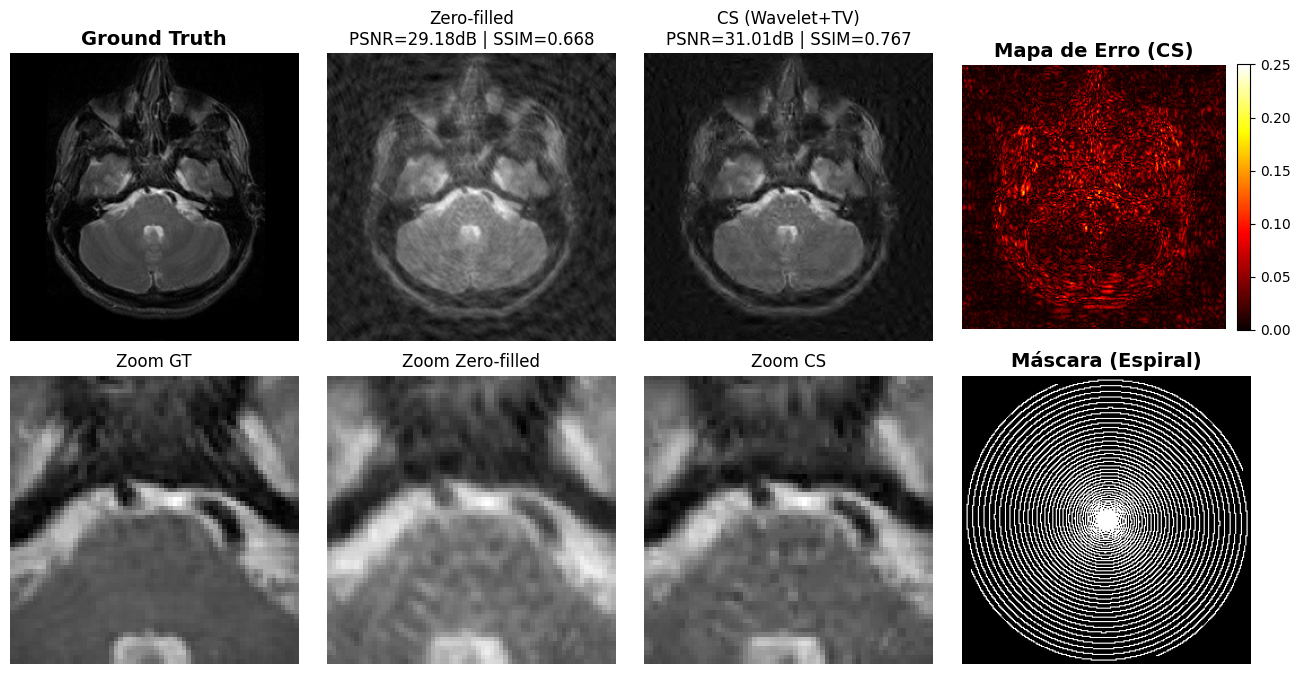

Figura salva como 'figura_resultados_spiral.png'


In [26]:
# %%
# ============================================================
# 12. FIGURA DE ALTA QUALIDADE PARA O ARTIGO
# ============================================================

# Escolhe uma fatia representativa (a que tiver PSNR mais próximo da média)
idx_rep = np.argmin(np.abs(df_results['psnr_cs'] - df_results['psnr_cs'].mean()))
print(f"Usando fatia índice {idx_rep} (mais próxima da média)")

gt = dataset[idx_rep].to(device)
mask = create_mask_spiral(gt.shape, ACCEL, device=device)
operator = MRIOperator(mask)
kspace_us = operator.forward(gt)

zf = operator.zero_filled(kspace_us)
rec = FISTA(config)
cs_img, _, _ = rec.solve(kspace_us, mask)

gt_np = gt.cpu().numpy()
zf_np = zf.cpu().numpy()
cs_np = cs_img.cpu().numpy()
mask_np = mask.cpu().numpy()

psnr_zf, ssim_zf, _ = compute_metrics(gt_np, zf_np)
psnr_cs, ssim_cs, _ = compute_metrics(gt_np, cs_np)

# Plot profissional
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 4, hspace=0.1, wspace=0.1)

# Linha 1: imagens
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(gt_np, cmap='gray')
ax1.set_title('Ground Truth', fontsize=14, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(zf_np, cmap='gray')
ax2.set_title(f'Zero-filled\nPSNR={psnr_zf:.2f}dB | SSIM={ssim_zf:.3f}', fontsize=12)
ax2.axis('off')

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(cs_np, cmap='gray')
ax3.set_title(f'CS (Wavelet+TV)\nPSNR={psnr_cs:.2f}dB | SSIM={ssim_cs:.3f}', fontsize=12)
ax3.axis('off')

ax4 = fig.add_subplot(gs[0, 3])
diff_plot = np.abs(gt_np - cs_np)
im4 = ax4.imshow(diff_plot, cmap='hot', vmin=0, vmax=0.25)
ax4.set_title('Mapa de Erro (CS)', fontsize=14, fontweight='bold')
ax4.axis('off')
plt.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)

# Linha 2: zoom
zoom_frac = 0.25
h, w = gt_np.shape
h_zoom = int(h * zoom_frac)
w_zoom = int(w * zoom_frac)
start_h = h//2 - h_zoom//2
start_w = w//2 - w_zoom//2

ax5 = fig.add_subplot(gs[1, 0])
ax5.imshow(gt_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax5.set_title('Zoom GT', fontsize=12)
ax5.axis('off')

ax6 = fig.add_subplot(gs[1, 1])
ax6.imshow(zf_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax6.set_title('Zoom Zero-filled', fontsize=12)
ax6.axis('off')

ax7 = fig.add_subplot(gs[1, 2])
ax7.imshow(cs_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax7.set_title('Zoom CS', fontsize=12)
ax7.axis('off')

ax8 = fig.add_subplot(gs[1, 3])
ax8.imshow(mask_np, cmap='gray')
ax8.set_title('Máscara (Espiral)', fontsize=14, fontweight='bold')
ax8.axis('off')

plt.tight_layout()
plt.savefig('figura_resultados_spiral.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figura salva como 'figura_resultados_spiral.png'")